# Antibiotic similarity from AMR literature and clinical AST

This exploratory notebook compares (1) bacterial species footprints in screened AMR literature, (2) Atlas feature profiles weighted by projected future scientific interest (SI), and (3) Atlas feature profiles weighted by clinical AST susceptible fractions. Analysis code lives in `exploratory_antibiotic_literature_similarity.py`; this notebook holds settings, result tables, and visualizations.

The data describe screened literature and submitted clinical AST records. They do not directly estimate antibiotic efficacy or population susceptibility.


## Sources and interpretation

- AMR literature pairs and forecast SI are read from this repository’s `outputs/parquets/` files. Pair counts are screened PubMed records, not isolate counts.
- Atlas feature vectors come from the sibling Pathogen Atlas V2 release and summarize question-answer prevalence in evidence-screened abstracts. They provide bacterial context, not susceptibility measurements.
- AST records come from the NCBI Pathogen Detection AST Browser. The analysis uses clinical, human-host, CLSI S/I/R calls, with conflicting isolate-drug calls excluded. AST records are submitter-provided and not centrally validated.
- Species names are joined after lowercasing and collapsing whitespace. Unmatched and missing pairs are not imputed as susceptible.

This is an exploratory representation comparison. Forecasts inherit the AMR screen’s `provisional_uncalibrated` provenance, and the NCBI AST sample is not population-representative.


## Parameters and run settings

Change the project and Atlas roots or the support thresholds below. Edit the exposed IMSTE parameter dictionary below; base, gravity, and mean-shift values configure both embeddings. The defaults follow the live IteratedMinimumSpanningTree checkout, with the current learning-rate override shown. Set `IMSTE_REPO_ROOT` if that checkout is elsewhere.


In [1]:
from pathlib import Path
import os
import sys
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "outputs/parquets/yearly_amr_screened_pairs.parquet").exists():
    candidates = [path for path in [PROJECT_ROOT, *PROJECT_ROOT.parents] if (path / "outputs/parquets/yearly_amr_screened_pairs.parquet").exists()]
    if not candidates:
        raise FileNotFoundError("Open this notebook from the AMR repository or one of its subdirectories.")
    PROJECT_ROOT = candidates[0]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DEFAULT_IMSTE_REPO_ROOT = Path("/Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree")
IMSTE_REPO_ROOT = Path(os.environ.get("IMSTE_REPO_ROOT", DEFAULT_IMSTE_REPO_ROOT)).expanduser().resolve()
if not (IMSTE_REPO_ROOT / "imste" / "_estimator.py").exists():
    raise FileNotFoundError(f"Live IMSTE source not found: {IMSTE_REPO_ROOT}")
sys.path.insert(0, str(IMSTE_REPO_ROOT))
import imste
IMSTE_SOURCE_FILE = Path(imste.__file__).resolve()
if IMSTE_REPO_ROOT not in IMSTE_SOURCE_FILE.parents:
    raise RuntimeError(
        f"IMSTE was already imported from {IMSTE_SOURCE_FILE}; restart the kernel to load the live repo at {IMSTE_REPO_ROOT}."
    )
print(f"IMSTE source: {IMSTE_SOURCE_FILE}")

from notebooks.exploratory_antibiotic_literature_similarity import AnalysisSettings, run_analysis, write_future_si_profile_payload

DEFAULT_ATLAS_ROOT = Path("/Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version2")
ATLAS_ROOT = Path(os.environ.get("ATLAS_V2_ROOT", DEFAULT_ATLAS_ROOT)).expanduser().resolve()

VECTOR_METRIC = "cosine"
MIN_SPECIES_PER_ANTIBIOTIC = 5
MIN_AVAILABLE_BACTERIA = 1
MIN_SHARED_SPECIES_FOR_DISPLAY = 1
AST_MIN_ISOLATES_PER_SPECIES_DRUG = 20
AST_MIN_SPECIES_PER_DRUG = 2
AST_MIN_TOTAL_ISOLATES_PER_DRUG = 30
AST_DATA_DIR = Path(os.environ.get("AST_COMPARISON_DATA_DIR", PROJECT_ROOT / "outputs/clinical_ast_comparison")).expanduser().resolve()

# Explicit IMSTE settings. These values are editable here and configure both embeddings.
# Values follow the inspected Atlas V2 Phase 5 settings, with a stable learning-rate override.
IMSTE_CONFIGURED_LEARNING_RATE = 0.05
IMSTE_PARAMETERS = {
    "imste_n_msts": 5,
    "imste_n_epochs": 2000,
    "imste_mst_method": "famst",
    "imste_mst_neighbors": 15,
    "imste_mst_inter_component_edges": 5,
    "imste_mst_max_neighbors": None,
    "imste_negative_ratio": 5,
    "imste_lambda_rep": 0.5,
    "imste_learning_rate": 0.001,
    "imste_batch_size": 32768,
    "imste_epsilon": 0.0001,
    "imste_logistic_margin": 1.0,
    "imste_logistic_temperature": 0.5,
    "imste_mst_representatives_per_component": 10,
    "imste_device": "auto",
    "imste_random_state": 42,
    # Gravity settings follow the live IteratedMinimumSpanningTree repository.
    # Gravity is disabled for the current cosine metric; it requires Euclidean.
    "gravity_mode": None,
    "gravity_neighbors": 15,
    "gravity_resolution": 0.7,
    "gravity_strength": 0.3,
    "gravity_core_quantile": 0.95,
    "gravity_mass_power": 0.5,
    "gravity_attraction_strength": 0.5,
    "gravity_near_repulsion_strength": 2.5,
    "gravity_force_neighbors": 8,
    "gravity_attraction_range": 1.0,
    "gravity_repulsion_range": 0.5,
    "gravity_step_size": 0.05,
    "gravity_iterations": 3,
    "gravity_pack_regions": False,
    "gravity_pack_radius_quantile": 0.9,
    "gravity_pack_gap_fraction": 0.25,
    # The live repository defaults: Gaussian mean shift runs after gravity/layout.
    "mean_shift_neighbors": 100,
    "mean_shift_bandwidth_factor": 7.0,
    "mean_shift_step_size": 0.9,
    "mean_shift_iterations": 1,
}
display(IMSTE_PARAMETERS)

settings = AnalysisSettings(
    project_root=PROJECT_ROOT,
    atlas_root=ATLAS_ROOT,
    ast_data_dir=AST_DATA_DIR,
    vector_metric=VECTOR_METRIC,
    min_species_per_antibiotic=MIN_SPECIES_PER_ANTIBIOTIC,
    min_available_bacteria=MIN_AVAILABLE_BACTERIA,
    min_shared_species_for_display=MIN_SHARED_SPECIES_FOR_DISPLAY,
    ast_min_isolates_per_species_drug=AST_MIN_ISOLATES_PER_SPECIES_DRUG,
    ast_min_species_per_drug=AST_MIN_SPECIES_PER_DRUG,
    ast_min_total_isolates_per_drug=AST_MIN_TOTAL_ISOLATES_PER_DRUG,
    imste_parameters=IMSTE_PARAMETERS,
    configured_imste_learning_rate=IMSTE_CONFIGURED_LEARNING_RATE,
)


IMSTE source: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/imste/__init__.py


{'imste_n_msts': 5,
 'imste_n_epochs': 2000,
 'imste_mst_method': 'famst',
 'imste_mst_neighbors': 15,
 'imste_mst_inter_component_edges': 5,
 'imste_mst_max_neighbors': None,
 'imste_negative_ratio': 5,
 'imste_lambda_rep': 0.5,
 'imste_learning_rate': 0.001,
 'imste_batch_size': 32768,
 'imste_epsilon': 0.0001,
 'imste_logistic_margin': 1.0,
 'imste_logistic_temperature': 0.5,
 'imste_mst_representatives_per_component': 10,
 'imste_device': 'auto',
 'imste_random_state': 42,
 'gravity_mode': None,
 'gravity_neighbors': 15,
 'gravity_resolution': 0.7,
 'gravity_strength': 0.3,
 'gravity_core_quantile': 0.95,
 'gravity_mass_power': 0.5,
 'gravity_attraction_strength': 0.5,
 'gravity_near_repulsion_strength': 2.5,
 'gravity_force_neighbors': 8,
 'gravity_attraction_range': 1.0,
 'gravity_repulsion_range': 0.5,
 'gravity_step_size': 0.05,
 'gravity_iterations': 3,
 'gravity_pack_regions': False,
 'gravity_pack_radius_quantile': 0.9,
 'gravity_pack_gap_fraction': 0.25,
 'mean_shift_neighb

In [2]:
# Run the analysis pipeline defined in the companion Python module.
analysis = run_analysis(settings)
globals().update(analysis)
write_future_si_profile_payload(analysis, PROJECT_ROOT / "sites/amr-si-explorer/dist/future_si_profiles.json")


AMR project: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Antimicrobial-Resistance
Atlas V2:    /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version2
Excluded 13 combination labels from AMR pair analysis: Amoxicillin/clavulanic-acid, Ampicillin/sulbactam, Ceftazidime/avibactam, Ceftolozane/tazobactam, Dalfopristin/quinupristin, Imipenem/cilastatin, Imipenem/cilastatin/relebactam, Meropenem/vaborbactam, Piperacillin/tazobactam, Sulfadiazine/trimethoprim, Sulfadimidine/trimethoprim, Sulfamethoxazole/trimethoprim, Sultamicillin
AMR screen provenance: {'holdout_precision': None, 'probability_threshold': 0.75, 'provisional_note': 'User-requested exploratory run before human calibration; do not interpret as meeting the precision target.', 'question_version': 'explicit-pair-resistance-noul-v1', 'run_id': 'jev-explicit-pair-resistance-v1-20261109', 'screening_source': 'system1', 'target_precision': 0.9, 'threshold_

/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


Spearman rank correlation between 73D cosine distances and 2D distances (excluding exact cosine ties): 0.517
NCBI data: loaded saved filtered source extract; source rows currently loaded=68,586
Filtered exact forecast/Atlas pairs: 68,586 rows, 130 species-drug cells, 16 species, 44 drugs
Dropped 21 conflicting isolate-drug groups (48 AST rows); retained only CLSI S/I/R calls.
Forecast pair overlap: 130/167 successful pairs have at least one clinical CLSI S/I/R call.
AST comparison support: 20 antibiotics meet >=2 species with >=20 AST each and >=30 isolates total.


/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


Same-basis map: 20 antibiotics, 78 species-drug cells, 73 Atlas features; min pair n=24, max pair n=3178.
73D cosine-distance concordance across 190 antibiotic pairs: Spearman rho=0.890; Pearson r=0.871.


## Literature footprint overview

The MDS chart projects Jaccard distances between each antibiotic’s observed bacterial species set. It is a view of recorded literature coverage; point distances in this projection only approximate the full Jaccard distances.


AMR provenance: {'holdout_precision': None, 'probability_threshold': 0.75, 'provisional_note': 'User-requested exploratory run before human calibration; do not interpret as meeting the precision target.', 'question_version': 'explicit-pair-resistance-noul-v1', 'run_id': 'jev-explicit-pair-resistance-v1-20261109', 'screening_source': 'system1', 'target_precision': 0.9, 'threshold_calibration_status': 'provisional_uncalibrated'}
Primary footprint antibiotics: 107; minimum species threshold: 5


,metric,value
0,distinct AMR pathogens,522
1,matched to Atlas feature matrix,517
2,unmatched to Atlas feature matrix,5
3,Atlas feature questions,73


,antibiotic_a,antibiotic_b,jaccard_similarity,shared_species,union_species,species_a,species_b
5441,Netilmicin,Arbekacin,0.750000,6,8,7,7
5271,Cefpirome,Netilmicin,0.600000,6,10,9,7
0,Erythromycin,Tetracycline,0.556364,153,275,224,204
725,Streptomycin,Kanamycin,0.527607,86,163,141,108
1666,Ceftazidime,Cefotaxime,0.503650,69,137,105,101
5282,Cefpirome,Mezlocillin,0.500000,5,10,9,6
5350,Sulfadiazine,Sulfadimethoxine,0.500000,5,10,8,7
5456,Netilmicin,Isepamicin,0.500000,4,8,7,5
5495,Arbekacin,Isepamicin,0.500000,4,8,7,5
5513,Eravacycline,Isepamicin,0.500000,4,8,7,5


,antibiotic_a,antibiotic_b,cosine_distance_73d,cosine_similarity_73d,imste_distance_2d,shared_species_count,shared_weight_mass
0,Amikacin,Amoxicillin,0.595476,0.404524,0.149389,1,0.175170
1,Amikacin,Ampicillin,0.500669,0.499331,0.195375,4,0.440024
2,Amikacin,Azithromycin,0.795539,0.204461,0.183062,1,0.125286
3,Amikacin,Aztreonam,0.049773,0.950227,0.011021,3,0.546879
4,Amikacin,Benzylpenicillin,0.547825,0.452175,0.179758,1,0.125286
5,Amikacin,Cefazolin,0.383585,0.616415,0.135065,1,0.175170
6,Amikacin,Cefepime,0.047338,0.952662,0.013690,3,0.567830
7,Amikacin,Cefixime,0.920109,0.079891,0.191283,0,0.000000
8,Amikacin,Cefotaxime,0.152209,0.847791,0.085406,3,0.488179
9,Amikacin,Cefoxitin,0.163239,0.836761,0.094708,3,0.460079


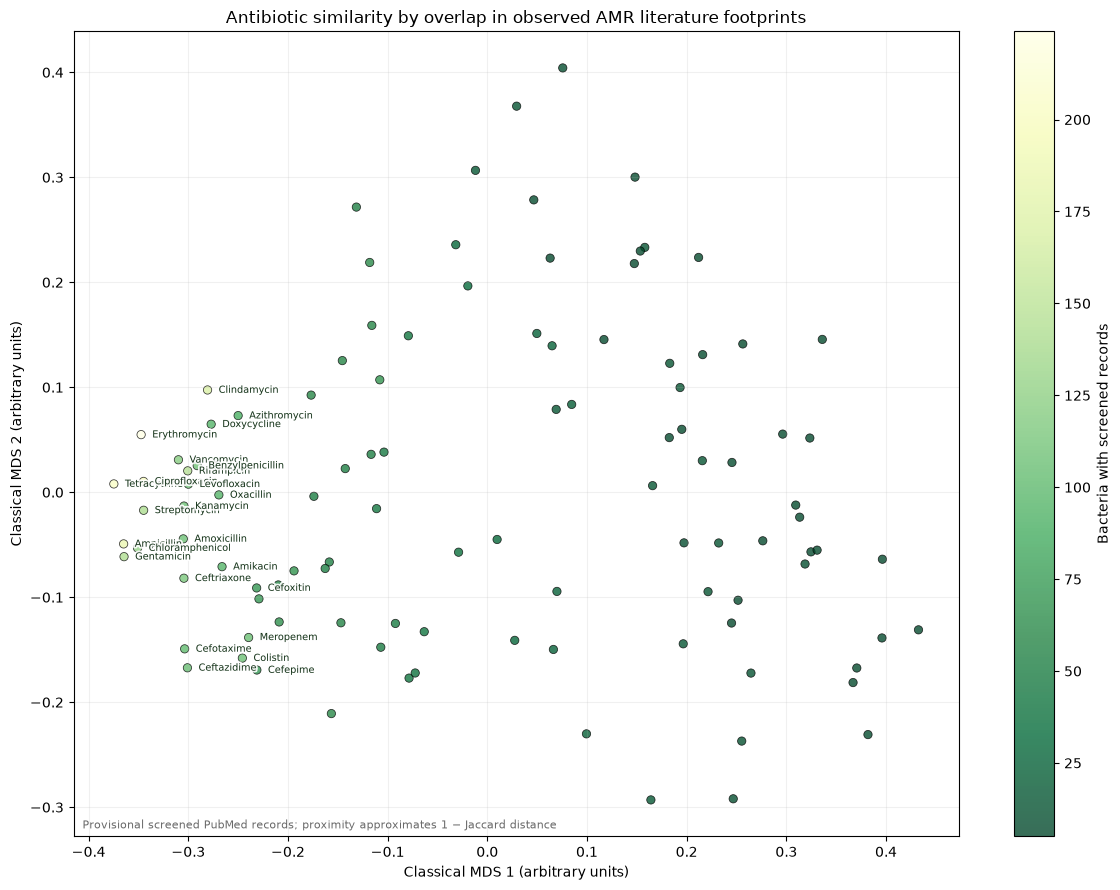

In [3]:
from IPython.display import display
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects

print(f"AMR provenance: {provenance or 'not available'}")
print(f"Primary footprint antibiotics: {len(footprints)}; minimum species threshold: {MIN_SPECIES_PER_ANTIBIOTIC}")
display(coverage)
display(closest_pairs.head(25))
display(profile_pair_diagnostics.head(25))

fig, ax = plt.subplots(figsize=(12, 9))
points = ax.scatter(
    coordinates.mds_1, coordinates.mds_2,
    c=coordinates.n_species_with_records, s=36, alpha=0.78, cmap="YlGn_r",
    edgecolors="black", linewidth=0.55,
)
for row in coordinates.nlargest(min(25, len(coordinates)), "n_species_with_records").itertuples(index=False):
    ax.annotate(
        row.antibiotic, (row.mds_1, row.mds_2), xytext=(8, 0), textcoords="offset points",
        ha="left", va="center", fontsize=7, color="#17351b", zorder=4,
        path_effects=[path_effects.withStroke(linewidth=2.6, foreground="white", alpha=0.9)],
    )
fig.colorbar(points, ax=ax, label="Bacteria with screened records")
ax.set_title("Antibiotic similarity by overlap in observed AMR literature footprints")
ax.set_xlabel("Classical MDS 1 (arbitrary units)")
ax.set_ylabel("Classical MDS 2 (arbitrary units)")
ax.text(0.01, 0.01, "Provisional screened PubMed records; proximity approximates 1 − Jaccard distance", transform=ax.transAxes, fontsize=8, color="dimgray")
ax.grid(alpha=0.18)
fig.tight_layout()
plt.show()


## Future-SI-weighted Atlas profiles

Each point is an antibiotic in the IMSTE projection. Names are arranged in a right-side column and connected to their points; the labels and connectors follow zoom and pan. Color and size summarize profile support, and hover gives the coverage and uncertainty diagnostics. Read similarity from the original 73D cosine distances rather than the 2D map.


In [ ]:
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

hover_columns = [
    "n_available_bacteria", "effective_sample_size", "largest_normalized_weight",
    "bootstrap_centroid_radius_95", "weighted_feature_dispersion",
]
antibiotic_map_figure = px.scatter(
    antibiotic_map, x="imste_1", y="imste_2",
    color="effective_sample_size", size="n_available_bacteria", size_max=20,
    text="antibiotic", custom_data=hover_columns, color_continuous_scale="YlGn_r",
    labels={"effective_sample_size": "Effective sample size (1 / sum of squared weights)", "imste_1": "IMSTE 1", "imste_2": "IMSTE 2"},
    title=("Future-SI-weighted Atlas profiles: cosine metric, IMSTE 2D projection"
           f"<br><sup>{int(selected_horizon.reference_year)} → {int(selected_horizon.future_year)}</sup>"),
)
antibiotic_map_figure.update_traces(
    mode="markers",
    marker={"line": {"color": "black", "width": 1.0}, "opacity": 0.88},
    hovertemplate=("<b>%{text}</b><br>Matched forecast bacteria: %{customdata[0]}<br>"
                   "Effective sample size: %{customdata[1]:.2f}<br>Largest normalized weight: %{customdata[2]:.3f}<br>"
                   "Bootstrap centroid radius (95th pct): %{customdata[3]:.3f}<br>Weighted feature dispersion: %{customdata[4]:.3f}<br>"
                   "IMSTE 1: %{x:.4f}<br>IMSTE 2: %{y:.4f}<extra></extra>"),
)
# Add a spaced right-hand label column. The connectors and labels use data
# coordinates, so they remain attached to each point while zooming or panning.
x_min, x_max = antibiotic_map.imste_1.min(), antibiotic_map.imste_1.max()
y_min, y_max = antibiotic_map.imste_2.min(), antibiotic_map.imste_2.max()
x_span = max(float(x_max - x_min), 1e-3)
y_span = max(float(y_max - y_min), 1e-3)
label_x = float(x_max + 0.07 * x_span)
x_axis_low = float(x_min - 0.05 * x_span)
x_axis_high = float(label_x + 0.42 * x_span)
y_axis_span = max(y_span * 1.08, (x_axis_high - x_axis_low) * 0.72)
y_axis_mid = float((y_min + y_max) / 2)
y_axis_low = y_axis_mid - y_axis_span / 2
y_axis_high = y_axis_mid + y_axis_span / 2
label_inset = 0.025 * y_axis_span
label_ys = np.linspace(y_axis_high - label_inset, y_axis_low + label_inset, len(antibiotic_map))
ordered_antibiotics = list(antibiotic_map.sort_values("imste_2", ascending=False).itertuples(index=False))
leader_x, leader_y = [], []
for row, label_y in zip(ordered_antibiotics, label_ys):
    leader_x.extend([float(row.imste_1), label_x, None])
    leader_y.extend([float(row.imste_2), float(label_y), None])
antibiotic_map_figure.add_trace(go.Scatter(
    x=leader_x, y=leader_y, mode="lines",
    line={"color": "#9aa79d", "width": 0.7}, hoverinfo="skip", showlegend=False,
))
antibiotic_map_figure.add_trace(go.Scatter(
    x=[label_x] * len(ordered_antibiotics), y=label_ys,
    text=[row.antibiotic for row in ordered_antibiotics],
    mode="text", textposition="middle right",
    textfont={"color": "#17351b", "size": 9},
    hoverinfo="skip", showlegend=False,
))
antibiotic_map_figure.update_layout(
    hovermode="closest", dragmode="zoom", width=1200, height=900,
    plot_bgcolor="white", paper_bgcolor="white",
    coloraxis_colorbar={"title": "Effective sample<br>size"},
    annotations=[{"text": "Exploratory context profile; not susceptibility", "xref": "paper", "yref": "paper", "x": 0.01, "y": 0.01, "showarrow": False, "xanchor": "left", "yanchor": "bottom", "font": {"size": 11, "color": "dimgray"}}],
    margin={"l": 70, "r": 40, "t": 100, "b": 70},
)
antibiotic_map_figure.update_xaxes(range=[x_axis_low, x_axis_high])
antibiotic_map_figure.update_xaxes(title_text="", range=[x_axis_low, x_axis_high], showticklabels=False, ticks="", showgrid=True, gridcolor="#e9eff6")
antibiotic_map_figure.update_yaxes(title_text="", range=[y_axis_low, y_axis_high], showticklabels=False, ticks="", showgrid=True, gridcolor="#e9eff6")
antibiotic_map_figure.show()


## Pairwise SI versus AST distances

Each dot is one unordered antibiotic pair. The x and y coordinates are cosine distances between the future-SI-weighted and AST-weighted profiles, respectively, using the same normalized 73D Atlas feature space and the same AST-supported species for both. Hover to read pair names and exact distances; the dashed line marks equal distances. The full table reports both distances and their absolute difference.


In [5]:
import numpy as np
import plotly.graph_objects as go

display(comparison_coverage.sort_values("forecast_antibiotic"))
display(pair_distance_comparison.sort_values("absolute_distance_difference", ascending=False))
# One point per unordered antibiotic pair. Hover to identify the pair and read exact distances.
max_pair_distance = float(pair_distance_comparison[["si_cosine_distance_73d", "ast_cosine_distance_73d"]].to_numpy().max())
axis_limit = max(0.05, max_pair_distance * 1.05)
fig_pair_distances = go.Figure()
fig_pair_distances.add_trace(go.Scatter(
    x=pair_distance_comparison.si_cosine_distance_73d,
    y=pair_distance_comparison.ast_cosine_distance_73d,
    mode="markers",
    marker={"size": 9, "color": "#33865c", "line": {"color": "#17351b", "width": 0.8}, "opacity": 0.82},
    customdata=np.column_stack([
        pair_distance_comparison.antibiotic_a,
        pair_distance_comparison.antibiotic_b,
        pair_distance_comparison.absolute_distance_difference,
    ]),
    hovertemplate=(
        "<b>%{customdata[0]} — %{customdata[1]}</b><br>"
        "Future-SI cosine distance: %{x:.4f}<br>"
        "AST cosine distance: %{y:.4f}<br>"
        "Absolute difference: %{customdata[2]:.4f}<extra></extra>"
    ),
    name="Antibiotic pair",
))
fig_pair_distances.add_trace(go.Scatter(
    x=[0, axis_limit], y=[0, axis_limit], mode="lines",
    line={"color": "#777777", "dash": "dash", "width": 1},
    hoverinfo="skip", name="Equal distances",
))
fig_pair_distances.update_layout(
    title=(
        "Pairwise antibiotic distances: future-SI profile vs clinical AST profile"
        f"<br><sup>{len(pair_distance_comparison)} pairs · 73D cosine distances · "
        f"Spearman ρ={rank_corr:.3f}, Pearson r={linear_corr:.3f}</sup>"
    ),
    xaxis_title="Future-SI-weighted profile cosine distance (73D Atlas feature space)",
    yaxis_title="AST-weighted profile cosine distance (same 73D feature space)",
    width=950, height=800, plot_bgcolor="white", paper_bgcolor="white",
    hovermode="closest", dragmode="zoom",
    xaxis={"range": [0, axis_limit], "showgrid": True, "gridcolor": "#e6ebe7"},
    yaxis={"range": [0, axis_limit], "showgrid": True, "gridcolor": "#e6ebe7", "scaleanchor": "x", "scaleratio": 1},
    legend={"x": 0.02, "y": 0.98},
    margin={"l": 100, "r": 40, "t": 105, "b": 100},
)
fig_pair_distances.add_annotation(
    text="Each dot is one unordered pair; points near the dashed line have similar distances under both weighting approaches.",
    xref="paper", yref="paper", x=0.01, y=-0.19, showarrow=False,
    xanchor="left", font={"size": 10, "color": "dimgray"},
)
fig_pair_distances.show()



,forecast_antibiotic,n_common_species,n_total_isolates,min_species_n,max_species_n,effective_sample_size,max_ast_weight,total_susceptible_mass,n_species_drug_cells,ast_centroid_radius_95_73d,bootstrap_draws_kept
0,Amikacin,4,4365,481,2849,3.824770,0.317519,3.118466,4,0.070282,500
1,Ampicillin,3,3654,34,3169,2.051398,0.592054,0.719533,3,0.608042,500
2,Aztreonam,3,2740,186,2339,1.813380,0.695148,1.256496,3,0.322785,500
3,Cefepime,3,3682,129,3137,2.631576,0.508698,1.724543,3,0.232062,500
4,Cefotaxime,2,266,57,209,1.507692,0.785714,0.223285,2,0.796966,500
5,Cefoxitin,3,1516,347,624,2.819502,0.393572,1.669478,3,0.111512,500
6,Ceftazidime,4,4303,404,2673,3.039435,0.457471,1.866177,4,0.141193,500
7,Ceftriaxone,3,4209,679,2824,2.326586,0.524729,1.889549,3,0.116942,500
8,Ciprofloxacin,10,6699,26,3178,8.129173,0.175704,5.196972,10,0.232093,500
9,Clindamycin,4,1082,28,888,2.928212,0.379426,2.577845,4,0.117602,500


,antibiotic_a,antibiotic_b,si_cosine_distance_73d,ast_cosine_distance_73d,absolute_distance_difference
121,Ceftriaxone,Tetracycline,0.247252,0.614008,0.366756
114,Ceftriaxone,Colistin,0.426696,0.756927,0.330230
122,Ceftriaxone,Tigecycline,0.416401,0.738346,0.321945
24,Ampicillin,Ceftriaxone,0.252556,0.565719,0.313163
117,Ceftriaxone,Gentamicin,0.340699,0.650031,0.309332
...,...,...,...,...,...
89,Cefoxitin,Colistin,0.275736,0.273032,0.002705
71,Cefotaxime,Ceftazidime,0.146524,0.143930,0.002595
183,Meropenem,Vancomycin,0.405479,0.403277,0.002202
63,Cefepime,Gentamicin,0.034795,0.035180,0.000386


## Clinical AST and future-SI comparison

The two maps show the future-SI and clinical-susceptibility weighted profiles fitted separately. Their axes can rotate or reflect independently; compare original-space distances in the scatter above. The AST support table shows species and isolate counts for the shared comparison set.


In [6]:
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

comparison_n = len(comparison_antibiotics)
antibiotic_color_map = {
    antibiotic: px.colors.qualitative.Dark24[i % len(px.colors.qualitative.Dark24)]
    for i, antibiotic in enumerate(comparison_antibiotics)
}

display(comparison_coverage.sort_values("forecast_antibiotic"))
fig_compare=make_subplots(rows=1,cols=2,subplot_titles=("Future-SI weights (shared AST-supported species)","Clinical susceptibility weights (same species)",),horizontal_spacing=.12)
fig_compare.layout.annotations=[]
for col, df_map in [(1, si_map_common), (2, ast_map_common)]:
    support=ast_map_common
    custom=np.column_stack([
        df_map.antibiotic.to_numpy(), support.n_common_species.to_numpy(),support.n_total_isolates.to_numpy(),
        support.min_species_n.to_numpy(),support.effective_sample_size.to_numpy(),support.ast_centroid_radius_95_73d.to_numpy()
    ])
    marker_size = 10  # Same small marker size in both panels.
    marker_color = [antibiotic_color_map[antibiotic] for antibiotic in df_map.antibiotic]
    fig_compare.add_trace(go.Scatter(
        x=df_map.x,y=df_map.y,mode="markers",
        marker={"size":marker_size,"color":marker_color,
                "line":{"color":"black","width":1},"opacity":.95},
        customdata=custom,
        hovertemplate=(
            "<b>%{customdata[0]}</b><br>Common species: %{customdata[1]}<br>Unique clinical CLSI isolates: %{customdata[2]}<br>"
            "Minimum isolates/species-drug: %{customdata[3]}<br>AST effective sample size: %{customdata[4]:.2f}<br>"
            "AST 95th pct bootstrap centroid radius (73D): %{customdata[5]:.3f}<extra></extra>"),
        name="Future SI" if col==1 else "Clinical AST",showlegend=False
    ),row=1,col=col)
    # Place labels in a readable right-hand column and connect each back to its point.
    span=max(float(df_map.x.max()-df_map.x.min()),1e-3)
    yspan=max(float(df_map.y.max()-df_map.y.min()),1e-3)
    label_x=float(df_map.x.max()+0.07*span)
    x_axis_low=float(df_map.x.min()-0.05*span)
    x_axis_high=float(label_x+0.36*span)
    # Equal aspect expands the y range to match the panel's x range. Reserve
    # that full displayed range for labels so they use the available plot height.
    y_axis_span=1.05*(x_axis_high-x_axis_low)
    y_axis_mid=float((df_map.y.min()+df_map.y.max())/2)
    y_axis_low=y_axis_mid-y_axis_span/2
    y_axis_high=y_axis_mid+y_axis_span/2
    # Use data coordinates for labels and leaders so they follow zoom and pan.
    label_inset = 0.035 * y_axis_span
    label_ys = np.linspace(y_axis_high - label_inset, y_axis_low + label_inset, len(df_map))
    xref, yref = ("x", "y") if col == 1 else ("x2", "y2")
    for row, label_y in zip(df_map.sort_values("y", ascending=False).itertuples(index=False), label_ys):
        fig_compare.add_shape(
            type="line", x0=float(row.x), y0=float(row.y), x1=label_x, y1=float(label_y),
            xref=xref, yref=yref, line={"color":"#9aa79d","width":.6}
        )
        fig_compare.add_annotation(
            x=label_x, y=float(label_y), xref=xref, yref=yref,
            text=str(row.antibiotic),showarrow=False,
            font={"size":9,"color":"#17351b"},
            xanchor="left",yanchor="middle",bgcolor="rgba(255,255,255,0.9)",
            borderpad=1,align="left"
        )
    fig_compare.update_xaxes(range=[x_axis_low,x_axis_high],row=1,col=col)
    fig_compare.update_yaxes(range=[y_axis_low,y_axis_high],row=1,col=col)
fig_compare.update_xaxes(title_text="IMSTE 1 (arbitrary orientation)",showgrid=False,zeroline=False)
fig_compare.update_yaxes(title_text="IMSTE 2 (arbitrary orientation)",showgrid=False,zeroline=False)
fig_compare.update_layout(
    title=f"Atlas V2 antibiotic profiles: projected SI vs clinical susceptibility<br><sup>{comparison_n} shared antibiotics · 73D cosine distance concordance Spearman ρ={rank_corr:.3f}</sup>",
    width=1500,height=760,plot_bgcolor="white",paper_bgcolor="white",hovermode="closest",dragmode="zoom",
    margin={"l":70,"r":90,"t":115,"b":90},font={"color":"#17351b"},
)
fig_compare.add_annotation(text="Two independently fitted maps; compare 73D distances, not absolute 2D coordinates. Clinical AST is submitter-reported CLSI, human clinical; not a population-representative estimate.",xref="paper",yref="paper",x=.01,y=-.10,showarrow=False,xanchor="left",font={"size":10,"color":"dimgray"})
fig_compare.show()
AST_HTML_PATH=AST_DATA_DIR / "clinical_ast_vs_future_si_imste.html"
fig_compare.write_html(AST_HTML_PATH,include_plotlyjs=True,full_html=True)
AST_PNG_PATH=AST_DATA_DIR / "clinical_ast_vs_future_si_imste.png"
fig_compare.write_image(AST_PNG_PATH,width=1800,height=950,scale=1.25)
print(f"Interactive comparison saved: {AST_HTML_PATH}")
print(f"Static preview saved: {AST_PNG_PATH}")


,forecast_antibiotic,n_common_species,n_total_isolates,min_species_n,max_species_n,effective_sample_size,max_ast_weight,total_susceptible_mass,n_species_drug_cells,ast_centroid_radius_95_73d,bootstrap_draws_kept
0,Amikacin,4,4365,481,2849,3.824770,0.317519,3.118466,4,0.070282,500
1,Ampicillin,3,3654,34,3169,2.051398,0.592054,0.719533,3,0.608042,500
2,Aztreonam,3,2740,186,2339,1.813380,0.695148,1.256496,3,0.322785,500
3,Cefepime,3,3682,129,3137,2.631576,0.508698,1.724543,3,0.232062,500
4,Cefotaxime,2,266,57,209,1.507692,0.785714,0.223285,2,0.796966,500
5,Cefoxitin,3,1516,347,624,2.819502,0.393572,1.669478,3,0.111512,500
6,Ceftazidime,4,4303,404,2673,3.039435,0.457471,1.866177,4,0.141193,500
7,Ceftriaxone,3,4209,679,2824,2.326586,0.524729,1.889549,3,0.116942,500
8,Ciprofloxacin,10,6699,26,3178,8.129173,0.175704,5.196972,10,0.232093,500
9,Clindamycin,4,1082,28,888,2.928212,0.379426,2.577845,4,0.117602,500


Interactive comparison saved: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Antimicrobial-Resistance/outputs/clinical_ast_comparison/clinical_ast_vs_future_si_imste.html
Static preview saved: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Antimicrobial-Resistance/outputs/clinical_ast_comparison/clinical_ast_vs_future_si_imste.png


## Reading the results

- AMR literature footprints summarize which bacteria have screened resistance-literature records. Missing pairs are unobserved, not susceptible.
- Forecast-weighted Atlas vectors represent projected scientific-interest weighting over bacterial evidence-context features. AST vectors use susceptible fractions from selected clinical CLSI records.
- AST records, forecast values, and Atlas features have different sources and coverage limits. Pairwise profile distances describe these constructed representations; they are not evidence of shared mechanism, clinical efficacy, or susceptibility.
- Small support counts and concentrated weights make individual profiles uncertain. Inspect support tables and bootstrap diagnostics alongside the maps.
